# R2H 1012 — 연구 종합 노트북 (결과 해석 · 심층 시각화)

R2H 2조의 10/11–10/12 연구를 한 곳에서 다시 확인하는 노트북이다. 모든 수치와 그림은 아래 두 가지에서만 나온다.

1. **SA_ETF 공개 결과표**: 커밋 SHA 로 고정한 URL 에서 받고, sha256 이 일치할 때만 쓴다. 원시 시세는 쓰지 않는다.
2. **R2H `src/r2h`**: 탐지·평가 계약 시연. 이 부분은 **합성 데이터**만 쓴다.

| 절 | 내용 | 원 연구 상태 |
|---|---|---|
| 1 | ETF Domain EDA — 20종의 상관·변동성·공통충격 구조 | CLOSED, 재현 확인 |
| 2 | Track A — KOSPI200 대비 상관 전환과 가격 사건 | CLOSED, **부정적 결과** |
| 3 | Track B — Lee·Kim·Lee (2020) SVR–GARCH CUSUM 재현 | 감사 종결, **METHOD_FIDELITY_UNRESOLVED** |
| 4 | R2H 계약 시연 — 탐지기 → 사건 매칭 → 오탐 상한 하 탐지율 | 합성 데이터 전용 (실제 성능 아님) |
| 5 | 종합 — 검증된 것 / 반증된 것 / 미결 | |

실행: `uv sync --extra dev --extra notebook` → `uv run jupyter execute notebooks/R2H_1012_research_synthesis.ipynb`.
처음 실행할 때만 네트워크가 필요하다. 받은 파일은 `outputs/cache/` 에 저장된다 (git 제외).

In [1]:
%matplotlib inline
import hashlib
import json
import urllib.request
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update(
    {
        "figure.dpi": 90,
        "savefig.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE = ROOT / "outputs" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


def show(fig, name: str) -> None:
    # Save a metadata-free PNG (byte-stable across runs) for the README, then display inline.
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", metadata={"Software": None})
    plt.show()


REPO = {
    "d5c2f792022d3c8efdbc52bdecd246b04bf32c45": "Siegfriex/SA_ETF",
    "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5": "Siegfriex/SA_ETF",
    "031157d27a715f108acee55d1dac30bd69fac78e": "Siegfriex/SA_ETF",
}
SOURCES = json.loads("""{
 "eda/universe_corr_pearson": {
  "sha": "d5c2f792022d3c8efdbc52bdecd246b04bf32c45",
  "path": "reports/tables/universe_corr_pearson.csv",
  "sha256": "46c82215e206abce0ca57fba0b1f4121c5fb9a5f9ec02be06d78b14943d0c9cc",
  "bytes": 3865
 },
 "eda/universe_vol_by_year": {
  "sha": "d5c2f792022d3c8efdbc52bdecd246b04bf32c45",
  "path": "reports/tables/universe_vol_by_year.csv",
  "sha256": "9a2d80460b71b76d7b82a076f04f056874fc344048e9c32bd6f398467d570146",
  "bytes": 1620
 },
 "eda/universe_rolling_state": {
  "sha": "d5c2f792022d3c8efdbc52bdecd246b04bf32c45",
  "path": "reports/tables/universe_rolling_state.csv",
  "sha256": "63b1b2555fe44d1109c426e19e4672ebb48aa25821d0d10043fc51454284dce4",
  "bytes": 101487
 },
 "eda/universe_breadth_daily": {
  "sha": "d5c2f792022d3c8efdbc52bdecd246b04bf32c45",
  "path": "reports/tables/universe_breadth_daily.csv",
  "sha256": "0506a22e26f99b56ec4558a78d8132470c052e0fb1476ce4fe32412a76aa4307",
  "bytes": 36244
 },
 "eda/etf_final_stats": {
  "sha": "d5c2f792022d3c8efdbc52bdecd246b04bf32c45",
  "path": "reports/tables/etf_final_stats.csv",
  "sha256": "eb18f6f4867c085a2345632b380ae468cb4f085e389d4be61d2ac26a424bef0b",
  "bytes": 7520
 },
 "trackA/a2/static_corr_by_period": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a2/static_corr_by_period.csv",
  "sha256": "5a24d8626dbf92d4d5c26e818c35b244eb2730ff3e7262cb743e45e1be411ba6",
  "bytes": 2348
 },
 "trackA/a2/crossing_counts": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a2/crossing_counts.csv",
  "sha256": "ebcfe13490e090d318e9a485e940cfd09f413821ff3d8ede0bc708240ddff1da",
  "bytes": 2326
 },
 "trackA/a2/regime_counts_by_rule": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a2/regime_counts_by_rule.csv",
  "sha256": "ab8ec97756fd1c52f0dfcc51aebff9e92979ebc5721427385c6cdab83755cb95",
  "bytes": 20265
 },
 "trackA/a2/lead_lag_corr": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a2/lead_lag_corr.csv",
  "sha256": "3261558d15e4835a55509ee6d6d65098432f80ffc64e4ee8cee2fdd52630ec98",
  "bytes": 21079
 },
 "trackA/a3/correlation_event_candidates": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a3/correlation_event_candidates.csv",
  "sha256": "2d36800fa7e3ab27f93e97d045920ba872a83f45b705794f8bdb5567862d44d3",
  "bytes": 1018699
 },
 "trackA/a3/mechanical_removed_retest": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a3/mechanical_removed_retest.csv",
  "sha256": "27447803e0c6a05a2a2bb796e288a69c8ff6b0b3cae088b23a93408e27cf52b0",
  "bytes": 17216
 },
 "trackA/a3/price_def_jaccard": {
  "sha": "a3f9e9b14a6980c84d2d417c7024e97c3e0eeee5",
  "path": "reports/r2h/research_a/a3/price_def_jaccard.csv",
  "sha256": "53dfda8e723c8a4ab988519d6012a89d8efbc3acd5bd630ca45f8eb316d2bd09",
  "bytes": 46012
 },
 "trackB/ORIGINAL_VS_REPRODUCED": {
  "sha": "031157d27a715f108acee55d1dac30bd69fac78e",
  "path": "research/track_b_paper2020/reports/ORIGINAL_VS_REPRODUCED.csv",
  "sha256": "1316c8e600ac64e64b7ba5985e9b57858dc0c20efd7b9f69ed01404d177ec773",
  "bytes": 22853
 },
 "trackB/EMPIRICAL_ORIGINAL_VS_REPRODUCED": {
  "sha": "031157d27a715f108acee55d1dac30bd69fac78e",
  "path": "research/track_b_paper2020/reports/EMPIRICAL_ORIGINAL_VS_REPRODUCED.csv",
  "sha256": "8b331ce1b5b42827a49477bec1859672467075469ce64395bf6a763e7e86a2f6",
  "bytes": 1978
 },
 "trackB/ABLATION_RESULTS": {
  "sha": "031157d27a715f108acee55d1dac30bd69fac78e",
  "path": "research/track_b_paper2020/reports/ABLATION_RESULTS.csv",
  "sha256": "3de0b1ea010ac6cbd69c6a7fb85de52278156f8948382ff07762876e321c0307",
  "bytes": 13792
 },
 "trackB/empirical_sp500_test": {
  "sha": "031157d27a715f108acee55d1dac30bd69fac78e",
  "path": "research/track_b_paper2020/results/empirical_sp500_test.csv",
  "sha256": "575b8796ef7fdf710908a86695e892b77967b5404ec85133fc12f582dcb4ef68",
  "bytes": 53088
 },
 "trackB/empirical_kospi_test": {
  "sha": "031157d27a715f108acee55d1dac30bd69fac78e",
  "path": "research/track_b_paper2020/results/empirical_kospi_test.csv",
  "sha256": "d8e094fa34cb6868004b4fce511410f52ebd20122cf5d2f98b51fc1e8a6103f3",
  "bytes": 73453
 },
 "trackB/empirical_krw_usd_test": {
  "sha": "031157d27a715f108acee55d1dac30bd69fac78e",
  "path": "research/track_b_paper2020/results/empirical_krw_usd_test.csv",
  "sha256": "5eaf7df680282a22e789661866fad5f6a0145bde1b12dcf6e876b0534d3bb759",
  "bytes": 54784
 }
}""")


def load(key: str, **kw) -> pd.DataFrame:
    # Download the pinned file once, verify sha256, then read it with pandas.
    s = SOURCES[key]
    f = CACHE / f"{s['sha'][:7]}__{s['path'].replace('/', '__')}"
    if not f.exists():
        url = f"https://raw.githubusercontent.com/{REPO[s['sha']]}/{s['sha']}/{s['path']}"
        f.write_bytes(urllib.request.urlopen(url, timeout=60).read())
    got = hashlib.sha256(f.read_bytes()).hexdigest()
    assert got == s["sha256"], f"sha256 mismatch for {key}: {got}"
    return pd.read_csv(f, **kw)


print(f"{len(SOURCES)} pinned sources, {sum(v['bytes'] for v in SOURCES.values()) / 1e6:.2f} MB")
pd.DataFrame(SOURCES).T[["sha", "path"]].assign(sha=lambda d: d.sha.str[:7])

18 pinned sources, 1.50 MB


,sha,path
eda/universe_corr_pearson,d5c2f79,reports/tables/universe_corr_pearson.csv
eda/universe_vol_by_year,d5c2f79,reports/tables/universe_vol_by_year.csv
eda/universe_rolling_state,d5c2f79,reports/tables/universe_rolling_state.csv
eda/universe_breadth_daily,d5c2f79,reports/tables/universe_breadth_daily.csv
eda/etf_final_stats,d5c2f79,reports/tables/etf_final_stats.csv
trackA/a2/static_corr_by_period,a3f9e9b,reports/r2h/research_a/a2/static_corr_by_perio...
trackA/a2/crossing_counts,a3f9e9b,reports/r2h/research_a/a2/crossing_counts.csv
trackA/a2/regime_counts_by_rule,a3f9e9b,reports/r2h/research_a/a2/regime_counts_by_rul...
trackA/a2/lead_lag_corr,a3f9e9b,reports/r2h/research_a/a2/lead_lag_corr.csv
trackA/a3/correlation_event_candidates,a3f9e9b,reports/r2h/research_a/a3/correlation_event_ca...


## 1. ETF Domain EDA — 20종 유니버스의 구조

원본은 SA_ETF `main@d5c2f79` 의 `reports/tables/` 이다. 2026-10-12 clean clone 에서 다시 실행했을 때 csv·png 309개가 바이트까지 같았다.

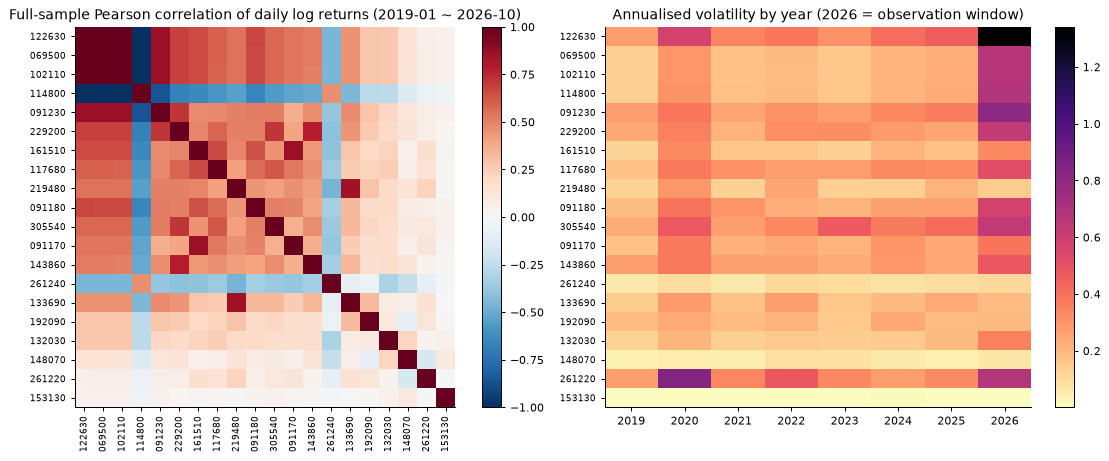

2026 / 2019-25 volatility ratio (top 5):
ticker
122630    3.32
102110    3.32
069500    3.30
114800    3.29
091230    2.55


In [2]:
corr = load("eda/universe_corr_pearson", index_col=0)
corr.columns = corr.columns.astype(str)
corr.index = corr.index.astype(str).str.zfill(6)
stats = load("eda/etf_final_stats", dtype={"ticker": str}).set_index("ticker")
order = corr.abs().sum().sort_values(ascending=False).index  # most-connected first
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(corr.loc[order, order], cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(20), order, rotation=90, fontsize=7)
ax[0].set_yticks(range(20), order, fontsize=7)
ax[0].grid(False)
ax[0].set_title("Full-sample Pearson correlation of daily log returns (2019-01 ~ 2026-10)")
fig.colorbar(im, ax=ax[0], fraction=0.046)
vol = load("eda/universe_vol_by_year", index_col=0)
vol.index = vol.index.astype(str).str.zfill(6)
im2 = ax[1].imshow(vol.loc[order], cmap="magma_r", aspect="auto")
ax[1].set_xticks(range(vol.shape[1]), vol.columns)
ax[1].set_yticks(range(20), order, fontsize=7)
ax[1].grid(False)
ax[1].set_title("Annualised volatility by year (2026 = observation window)")
fig.colorbar(im2, ax=ax[1], fraction=0.046)
plt.tight_layout()
show(fig, "eda_corr_vol")
ratio = (stats["vol_2026"] / stats["vol_2019_25"]).sort_values(ascending=False)
print("2026 / 2019-25 volatility ratio (top 5):")
print(ratio.head().round(2).to_string())
assert abs(corr.loc["069500", "148070"] - 0.134) < 5e-4 and abs(ratio["069500"] - 3.30) < 0.01

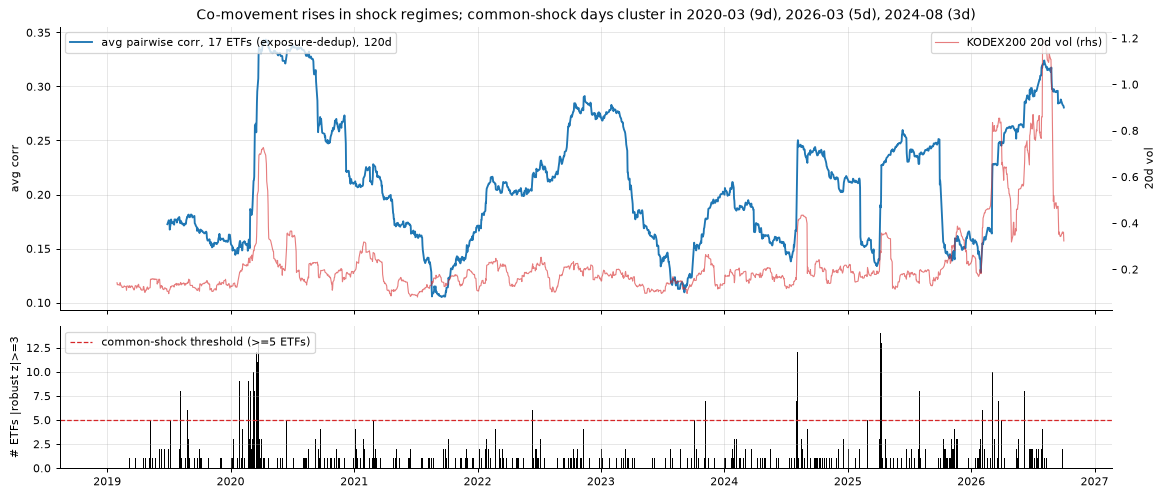

common-shock days (>=5 ETFs): 40 | top months: {Period('2020-03', 'M'): 9, Period('2026-03', 'M'): 5, Period('2024-08', 'M'): 3}


In [3]:
st = load("eda/universe_rolling_state", parse_dates=["Date"]).set_index("Date")
br = load("eda/universe_breadth_daily", parse_dates=["Date"]).set_index("Date")
fig, ax = plt.subplots(2, 1, figsize=(13, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(
    st.index,
    st["avgcorr_dedup17_120d"],
    color="C0",
    label="avg pairwise corr, 17 ETFs (exposure-dedup), 120d",
)
ax0b = ax[0].twinx()
ax0b.plot(st.index, st["vol20_069500"], color="C3", alpha=0.6, lw=0.9, label="KODEX200 20d vol (rhs)")
ax0b.grid(False)
ax[0].set_ylabel("avg corr")
ax0b.set_ylabel("20d vol")
ax[0].legend(loc="upper left")
ax0b.legend(loc="upper right")
ax[1].bar(br.index, br["n_rz3D_dedup"], width=2, color="k")
ax[1].axhline(5, color="C3", ls="--", lw=1, label="common-shock threshold (>=5 ETFs)")
ax[1].legend(loc="upper left")
ax[1].set_ylabel("# ETFs |robust z|>=3")
top = br.index[br["n_rz3D_dedup"] >= 5].to_period("M").value_counts().head(3)
ax[0].set_title(
    "Co-movement rises in shock regimes; common-shock days cluster in "
    + ", ".join(f"{p} ({n}d)" for p, n in top.items())
)
plt.tight_layout()
show(fig, "eda_comovement_shocks")
n_common = int((br["n_rz3D_dedup"] >= 5).sum())
print("common-shock days (>=5 ETFs):", n_common, "| top months:", top.to_dict())
assert n_common == 40

**해석 (EDA)**
- 국내 주식형 ETF 끼리는 상관이 0.5–1.0 으로 높고, KOSPI200 계열 4종(069500·102110·122630·114800)은 사실상 같은 노출이다(인버스 포함 |ρ|≈1).
  그래서 R2H 계약은 이 4종을 **사건 1건**으로 센다.
- 채권(148070·153130)·금·원유는 KOSPI200 과 거의 독립이고(ρ 0.05–0.27), 달러선물(261240)만 일관되게 음(−0.46)이다.
- 2026 은 069500 변동성이 2019–25 평균의 **3.3배**인 특이 국면이다. 공통충격일(robust-z ≥ 3 인 ETF 5개 이상) 40일도 고변동기에 몰려 있다.
  2026 을 holdout 으로 쓸지는 미결정(D-03)이며, 이미 탐색에 쓰인 구간이라 blind holdout 이 아니다.
- 평균 상관은 충격 국면에서 계단식으로 오른다. 따라서 "상관 변화" 와 "변동성 국면" 은 서로 독립인 신호가 아니다. 2절의 귀무검정 해석은 이 점을 전제로 읽어야 한다.

## 2. Track A — 상관 전환은 급등의 정답·조기경보가 될 수 있는가

원본: SA_ETF `codex/r2h-track-a@a3f9e9b`. 독립 2회 재실행에서 결과표 43종이 원본과 같았고, 보고서 claim 29개 중 27개가 일치했다.
기준 069500(KOSPI200), 대조 102110. 30/60/120 거래일 rolling 상관을 쓴다.

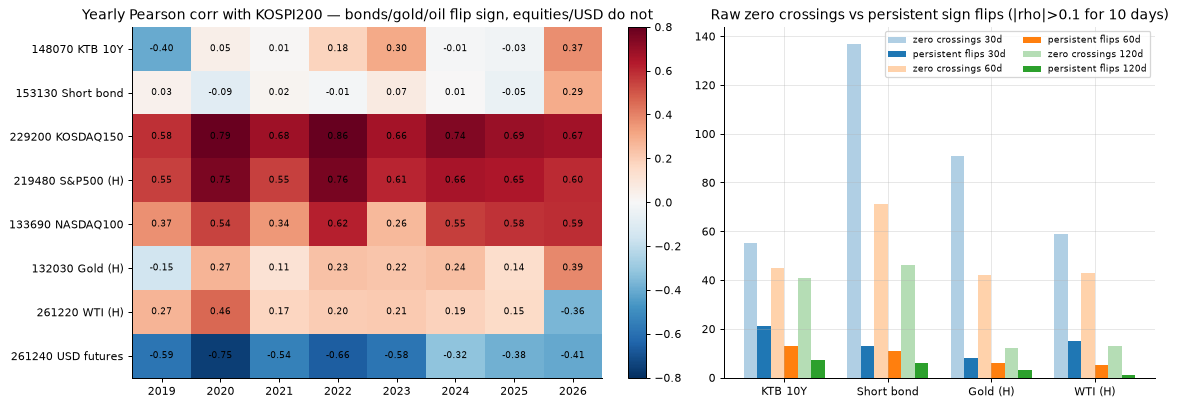

In [4]:
NAMES = {
    "148070": "KTB 10Y",
    "153130": "Short bond",
    "229200": "KOSDAQ150",
    "219480": "S&P500 (H)",
    "133690": "NASDAQ100",
    "132030": "Gold (H)",
    "261220": "WTI (H)",
    "261240": "USD futures",
    "102110": "TIGER200 (control)",
}
pairs = list(NAMES)
sc = load("trackA/a2/static_corr_by_period", dtype={"ticker": str}).set_index("ticker")
years = [c for c in sc.columns if c.startswith("y")]
cc = load("trackA/a2/crossing_counts", dtype={"ticker": str})
rc = load("trackA/a2/regime_counts_by_rule", dtype={"ticker": str})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
m = sc.loc[pairs[:-1], years].astype(float)
im = ax[0].imshow(m, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax[0].grid(False)
ax[0].set_xticks(range(len(years)), [y[1:] for y in years])
ax[0].set_yticks(range(len(m)), [f"{t} {NAMES[t]}" for t in m.index])
for (i, j), v in np.ndenumerate(m.to_numpy()):
    ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
ax[0].set_title("Yearly Pearson corr with KOSPI200 — bonds/gold/oil flip sign, equities/USD do not")
fig.colorbar(im, ax=ax[0], fraction=0.04)
z = cc[(cc.method == "pearson")].pivot(index="ticker", columns="window", values="n_zero_cross")
r = rc[(rc.method == "pearson") & (rc.rule == "b0.100_k10")].pivot(
    index="ticker", columns="window", values="n_sign_changes"
)
sel = ["148070", "153130", "132030", "261220"]
x = np.arange(len(sel))
w = 0.13
for k, win in enumerate([30, 60, 120]):
    ax[1].bar(
        x + (k - 1) * 2 * w - w / 2,
        z.loc[sel, win],
        w,
        color=f"C{k}",
        alpha=0.35,
        label=f"zero crossings {win}d",
    )
    ax[1].bar(
        x + (k - 1) * 2 * w + w / 2, r.loc[sel, win], w, color=f"C{k}", label=f"persistent flips {win}d"
    )
ax[1].set_xticks(x, [NAMES[t] for t in sel])
ax[1].legend(fontsize=7, ncol=2)
ax[1].set_title("Raw zero crossings vs persistent sign flips (|rho|>0.1 for 10 days)")
plt.tight_layout()
show(fig, "trackA_yearly_corr_flips")
assert int(r.loc["148070", 60]) == 13 and abs(float(sc.loc["148070", "y2019"]) + 0.404) < 5e-4

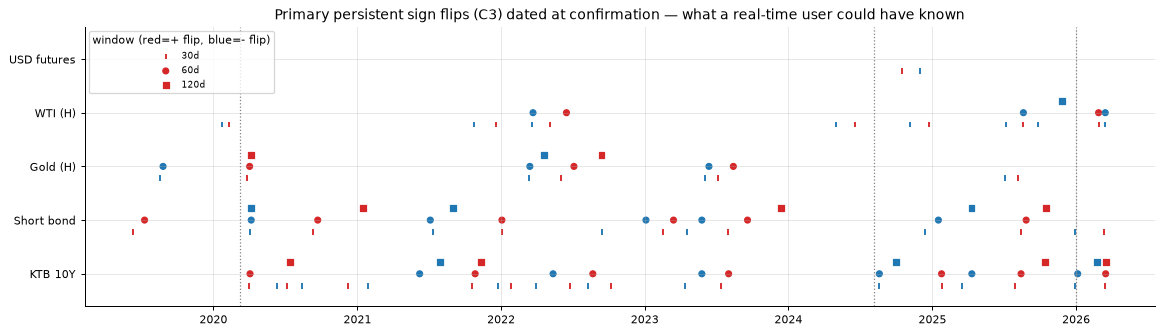

C3 primary events: 111 | mean candidate->confirmation (calendar days) by window: {'120': 14.4, '30': 13.1, '60': 13.3}


In [5]:
ce = load(
    "trackA/a3/correlation_event_candidates",
    dtype={"series_id": str},
    parse_dates=["candidate_at", "confirmed_at"],
)
c3 = ce[
    (ce.definition_id == "C3_sign_regime")
    & (ce.parameter_set == '{"band": 0.1, "persist": 10}')
    & (ce.method == "pearson")
]
lag_td = c3.groupby("window").apply(
    lambda g: (g.confirmed_at - g.candidate_at).dt.days.mean(), include_groups=False
)
fig, ax = plt.subplots(figsize=(13, 3.8))
tick = [t for t in pairs if t in set(c3.series_id)]
for i, t in enumerate(tick):
    for win, mk in [(30, "|"), (60, "o"), (120, "s")]:
        g = c3[(c3.series_id == t) & (c3.window.astype(str) == str(win))]
        ax.scatter(
            g.confirmed_at,
            np.full(len(g), i) + {30: -0.22, 60: 0, 120: 0.22}[win],
            c=np.where(g.direction > 0, "C3", "C0"),
            marker=mk,
            s=22,
            label=f"{win}d" if i == 0 else None,
        )
ax.set_yticks(range(len(tick)), [NAMES[t] for t in tick])
ax.set_ylim(-0.6, len(tick) - 0.4)
for d in ["2020-03-09", "2024-08-05", "2026-01-01"]:
    ax.axvline(pd.Timestamp(d), color="grey", ls=":", lw=1)
ax.legend(title="window (red=+ flip, blue=- flip)", fontsize=7, loc="upper left")
ax.set_title(
    "Primary persistent sign flips (C3) dated at confirmation — what a real-time user could have known"
)
plt.tight_layout()
show(fig, "trackA_c3_timeline")
print(
    "C3 primary events:",
    len(c3),
    "| mean candidate->confirmation (calendar days) by window:",
    lag_td.round(1).to_dict(),
)
assert len(c3) == 111

**해석 (상관 국면)**
- 148070(국고채10년) 의 연도별 상관은 2019 −0.40 → 2026 +0.37 로 **부호가 바뀐다**. "주식–채권 음(−)의 상관(헤지)" 은 2019 에만 성립했다.
- 0선 교차(옅은 막대)는 창이 짧을수록 많고 대부분 잡음이다. 독립 난수 쌍에서도 수십 번 생긴다.
  지속성 규칙(|ρ|>0.1 이 10일 연속)을 통과한 전환(짙은 막대)만 국면 후보로 남는데, 148070 60일 창에서 45 → **13건**이다.
- 지속 전환은 정의상 **9 거래일 뒤에야 확정**된다(위 그림은 확정 시점 기준). 후보일(candidate_at)을 실시간 신호로 쓰면 미래 정보가 섞인다.
- 코스닥·미국주식은 상관이 항상 양(+), 달러는 항상 음(−)이라 전환 사건이 생기지 않는다. 따라서 "상관 전환 → 급등" 가설이 적용될 수 있는 대상은 채권·금·원유뿐이다.

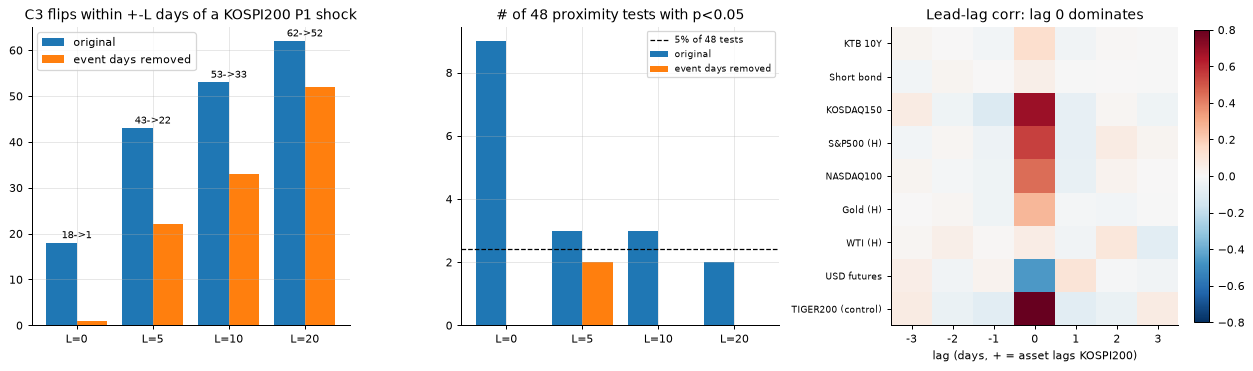

         T_orig  T_masked  sig_orig  sig_masked   n
max_lag                                            
0            18         1         9           0  48
5            43        22         3           2  48
10           53        33         3           0  48
20           62        52         2           0  48
assets whose |rho| peaks away from lag 0: {'261220': 2}


In [6]:
mr = load("trackA/a3/mechanical_removed_retest", dtype={"ticker": str})
agg = mr.groupby("max_lag").agg(
    T_orig=("T_obs_orig", "sum"),
    T_masked=("T_obs_masked", "sum"),
    sig_orig=("p_value_orig", lambda p: int((p < 0.05).sum())),
    sig_masked=("p_value_masked", lambda p: int((p < 0.05).sum())),
    n=("p_value_orig", "size"),
)
ll = load("trackA/a2/lead_lag_corr", dtype={"ticker": str})
full = ll[ll.period == "full"].pivot(index="ticker", columns="lag", values="rho")
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
x = np.arange(len(agg))
ax[0].bar(x - 0.2, agg.T_orig, 0.4, label="original")
ax[0].bar(x + 0.2, agg.T_masked, 0.4, label="event days removed")
ax[0].set_xticks(x, [f"L={lag}" for lag in agg.index])
ax[0].set_title("C3 flips within +-L days of a KOSPI200 P1 shock")
ax[0].legend()
for i, (a, b) in enumerate(zip(agg.T_orig, agg.T_masked, strict=True)):
    ax[0].text(i, max(a, b) + 1, f"{a}->{b}", ha="center", fontsize=8)
ax[1].bar(x - 0.2, agg.sig_orig, 0.4, label="original")
ax[1].bar(x + 0.2, agg.sig_masked, 0.4, label="event days removed")
ax[1].axhline(48 * 0.05, color="k", ls="--", lw=1, label="5% of 48 tests")
ax[1].set_xticks(x, [f"L={lag}" for lag in agg.index])
ax[1].set_title("# of 48 proximity tests with p<0.05")
ax[1].legend(fontsize=7)
fl = full.loc[[t for t in pairs if t in full.index]]
im = ax[2].imshow(fl, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax[2].grid(False)
ax[2].set_xticks(range(fl.shape[1]), fl.columns)
ax[2].set_yticks(range(len(fl)), [NAMES[t] for t in fl.index], fontsize=7)
ax[2].set_xlabel("lag (days, + = asset lags KOSPI200)")
ax[2].set_title("Lead-lag corr: lag 0 dominates")
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout()
show(fig, "trackA_mechanical_leadlag")
print(agg.to_string())
assert (agg.loc[0, "T_orig"], agg.loc[0, "T_masked"], agg.loc[0, "sig_orig"], agg.loc[0, "sig_masked"]) == (
    18,
    1,
    9,
    0,
)
argmax = full.abs().idxmax(axis=1)
print("assets whose |rho| peaks away from lag 0:", argmax[argmax != 0].to_dict())

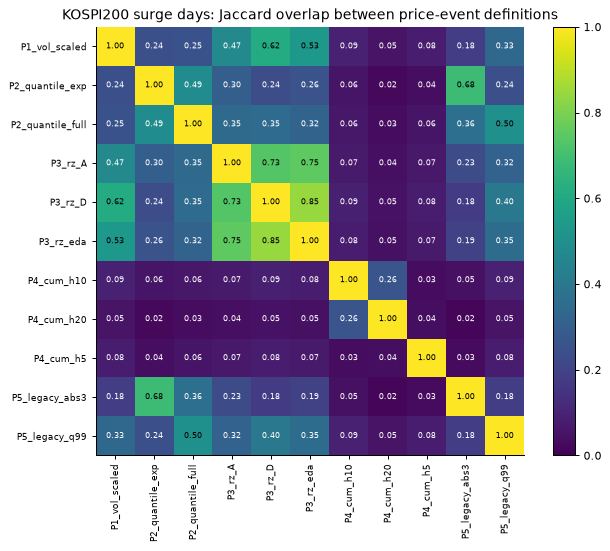

In [7]:
jac = load("trackA/a3/price_def_jaccard", dtype={"series_id": str})
j = jac[(jac.series_id == "069500") & (jac.direction == 1)]
defs = sorted(set(j.def_a) | set(j.def_b))
M = pd.DataFrame(np.eye(len(defs)), index=defs, columns=defs)
for r_ in j.itertuples():
    M.loc[r_.def_a, r_.def_b] = M.loc[r_.def_b, r_.def_a] = r_.jaccard
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(defs)), defs, rotation=90, fontsize=7)
ax.set_yticks(range(len(defs)), defs, fontsize=7)
for (a, b), v in np.ndenumerate(M.to_numpy()):
    ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=6, color="w" if v < 0.5 else "k")
ax.set_title("KOSPI200 surge days: Jaccard overlap between price-event definitions")
fig.colorbar(im, fraction=0.046)
plt.tight_layout()
show(fig, "trackA_price_def_jaccard")

**해석 (근접·선행성)**
- KOSPI200 의 큰 수익률일(P1, 28일)을 두 시계열에서 지우고 상관 전환을 다시 만들면, 같은 날(L=0) 근접은 **18 → 1건**, 유의 검정은 **9/48 → 0/48** 로 줄어든다.
  같은 날 일치는 "같은 큰 수익률이 가격 사건과 상관 변화로 두 번 세어진 것" 으로 거의 다 설명된다.
- 매칭 폭을 넓히면(L=5–20) 유의 비율이 우연 수준(5%) 근처로 내려간다. 전체 45,280 검정의 p<0.05 비율은 L=0/5/10/20 에서 11.2/8.0/6.8/5.1% 이다.
- lead-lag 상관도 lag 0 이 지배적이다. 원 보고서는 "모든 자산에서 lag 0 이 최대" 라고 적었지만, **WTI(261220) 는 lag +2 가 더 크다** (0.093 vs 0.060, 모두 |ρ|<0.1). 결론("선행 관계 없음")은 그대로다.
- 가격 사건 정의끼리도 겹침이 작다. robust-z 3종 사이 Jaccard 는 0.73–0.85, 일간 정의와 누적(P4) 정의 사이는 0.02–0.09 이다. "급등" 은 하나의 사건 집합이 아니며, **Ground Truth 정의를 먼저 확정해야(D-01)** 탐지율을 매길 수 있다.

**Track A 결론** — 상관 전환을 급등의 Ground Truth 나 조기 경보로 쓸 근거는 이 데이터에서 발견되지 않았다. 효과가 없다는 증명은 아니고, 현재 정의·표본·검정력에서의 부정적 결과다.

## 3. Track B — Lee·Kim·Lee (2020) Hybrid SVR–GARCH CUSUM 재현

원본: SA_ETF `research/track-b-paper2020@031157d`. 재현 감사에서 pytest 84/84 를 통과했고, 실증 결과가 바이트 동일하게 다시 나왔으며, MC 400회를 다시 생성해 완전히 일치했다.
판정은 **METHOD_FIDELITY_UNRESOLVED** 이다 (원문 수치 미재현).

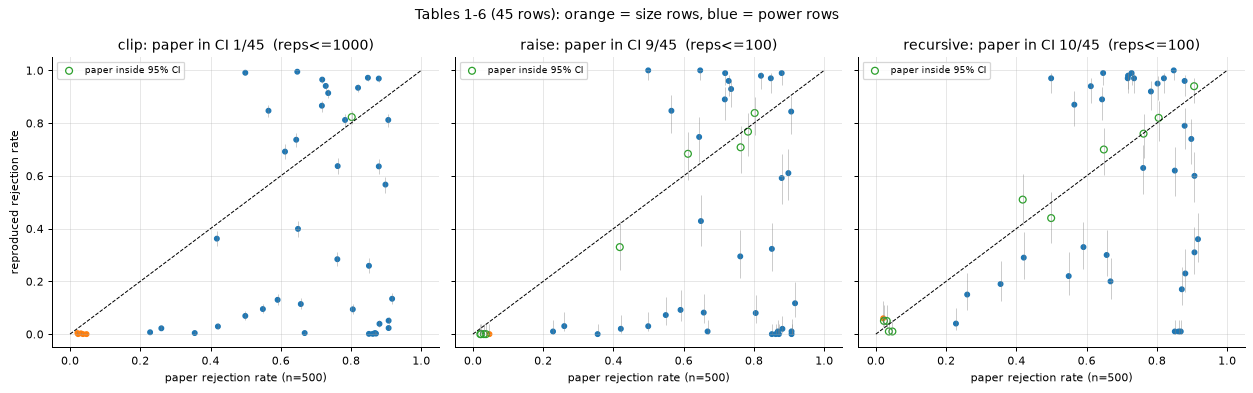

{'clip': 1, 'raise': 9, 'recursive': 10}


In [8]:
ovr = load("trackB/ORIGINAL_VS_REPRODUCED")
o5 = ovr[ovr.n == 500]
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for a, lane in zip(ax, ["clip", "raise", "recursive"], strict=True):
    d = o5.dropna(subset=[f"{lane}_rate_cond_ok"])
    inside = d[f"{lane}_paper_in_ci"].astype(str).eq("True")
    yerr = np.vstack(
        [d[f"{lane}_rate_cond_ok"] - d[f"{lane}_ci_lo"], d[f"{lane}_ci_hi"] - d[f"{lane}_rate_cond_ok"]]
    )
    a.errorbar(d.paper, d[f"{lane}_rate_cond_ok"], yerr=yerr, fmt="none", ecolor="grey", alpha=0.4, lw=0.8)
    a.scatter(
        d.paper[~inside],
        d[f"{lane}_rate_cond_ok"][~inside],
        s=14,
        c=np.where(d.kind[~inside] == "size", "C1", "C0"),
    )
    a.scatter(
        d.paper[inside],
        d[f"{lane}_rate_cond_ok"][inside],
        s=30,
        facecolors="none",
        edgecolors="C2",
        label="paper inside 95% CI",
    )
    a.plot([0, 1], [0, 1], "k--", lw=0.8)
    a.set_xlabel("paper rejection rate (n=500)")
    reps = int(d[f"{lane}_reps"].max())
    a.set_title(f"{lane}: paper in CI {int(inside.sum())}/{len(d)}  (reps<={reps})")
    a.legend(fontsize=7, loc="upper left")
ax[0].set_ylabel("reproduced rejection rate")
fig.suptitle("Tables 1-6 (45 rows): orange = size rows, blue = power rows")
plt.tight_layout()
show(fig, "trackB_tables_paper_vs_repro")
cov = {
    lane: int(o5[f"{lane}_paper_in_ci"].astype(str).eq("True").sum())
    for lane in ["clip", "raise", "recursive"]
}
print(cov)
assert cov == {"clip": 1, "raise": 9, "recursive": 10}

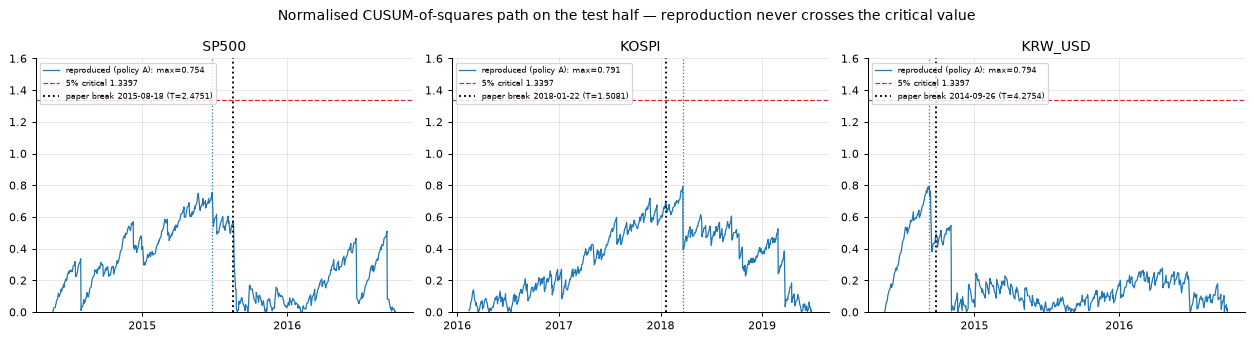

,series,test_policy,nonpos_policy,paper_T,repl_T,repl_reject,paper_date,repl_date
0,sp500,A observed-proxy,raise,2.4751,0.7540,False,2015-08-18,2015-06-26
1,sp500,A observed-proxy,clip,2.4751,0.7540,False,2015-08-18,2015-06-26
2,sp500,B recursive,clip,2.4751,1.0963,False,2015-08-18,2015-08-18
3,kospi,A observed-proxy,raise,1.5081,0.7910,False,2018-01-22,2018-03-22
4,kospi,A observed-proxy,clip,1.5081,0.7910,False,2018-01-22,2018-03-22
5,kospi,B recursive,clip,1.5081,1.1071,False,2018-01-22,2017-11-24
6,krw_usd,A observed-proxy,raise,4.2754,0.7939,False,2014-09-26,2014-09-09
7,krw_usd,A observed-proxy,clip,4.2754,0.7939,False,2014-09-26,2014-09-09
8,krw_usd,B recursive,clip,4.2754,1.0238,False,2014-09-26,2014-09-09
9,sp500,A observed-proxy,clip,2.4751,0.8134,False,2015-08-18,2015-06-26


In [9]:
emp = load("trackB/EMPIRICAL_ORIGINAL_VS_REPRODUCED")
CRIT = 1.3397
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, s in zip(ax, ["sp500", "kospi", "krw_usd"], strict=True):
    t = load(f"trackB/empirical_{s}_test", parse_dates=["date"])
    e = t["residual"].to_numpy()
    tau = np.sqrt(np.mean(e**4) - np.mean(e**2) ** 2)
    path = np.abs(t["centered_path"].to_numpy()) / (np.sqrt(len(e)) * tau)
    row = emp[(emp.series == s)].iloc[0]
    a.plot(t["date"], path, lw=1, label=f"reproduced (policy A): max={path.max():.3f}")
    a.axhline(CRIT, color="C3", ls="--", lw=1, label="5% critical 1.3397")
    a.axvline(
        pd.Timestamp(row.paper_date),
        color="k",
        ls=":",
        label=f"paper break {row.paper_date} (T={row.paper_T})",
    )
    a.axvline(t["date"].iloc[path.argmax()], color="C0", ls=":", lw=1)
    a.set_title(s.upper())
    a.legend(fontsize=6.5, loc="upper left")
    a.set_ylim(0, max(1.6, path.max() * 1.1))
    a.xaxis.set_major_locator(mdates.YearLocator())
    a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    assert abs(path.max() - float(row.repl_T)) < 1e-3, (s, path.max(), row.repl_T)
fig.suptitle(
    "Normalised CUSUM-of-squares path on the test half — reproduction never crosses the critical value"
)
plt.tight_layout()
show(fig, "trackB_empirical_cusum")
emp[["series", "test_policy", "nonpos_policy", "paper_T", "repl_T", "repl_reject", "paper_date", "repl_date"]]

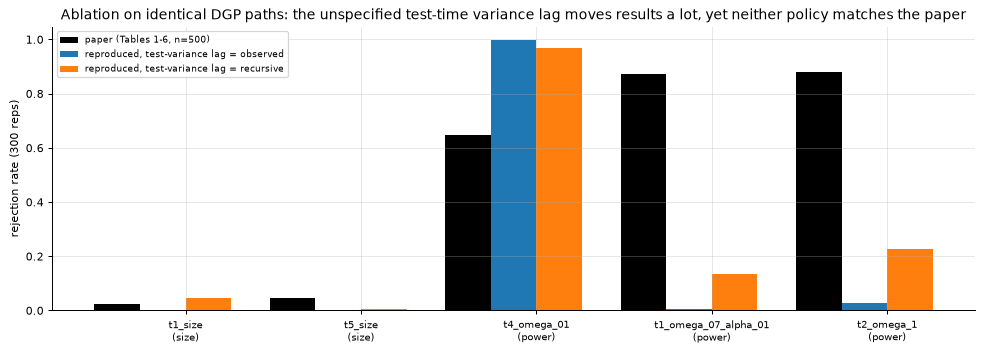

In [10]:
ab = load("trackB/ABLATION_RESULTS")
b = ab[ab.variant == "baseline"].pivot(index="case_id", columns="test_policy", values="reject_rate")
paper = ab[ab.variant == "baseline"].drop_duplicates("case_id").set_index("case_id")["paper_n500"]
kind = ab[ab.variant == "baseline"].drop_duplicates("case_id").set_index("case_id")["kind"]
fig, ax = plt.subplots(figsize=(11, 4))
o = list(paper.sort_values().index)
x = np.arange(len(o))
w = 0.26
ax.bar(x - w, paper[o], w, color="k", label="paper (Tables 1-6, n=500)")
for k, (pol, c) in enumerate(zip(b.columns, ["C0", "C1", "C2"][: len(b.columns)], strict=True)):
    ax.bar(x + k * w, b.loc[o, pol], w, color=c, label=f"reproduced, test-variance lag = {pol}")
ax.set_xticks(x + w / 2, [f"{i}\n({kind[i]})" for i in o], fontsize=8)
ax.set_ylabel("rejection rate (300 reps)")
ax.legend(fontsize=7)
ax.set_title(
    "Ablation on identical DGP paths: the unspecified test-time variance lag moves results a lot,"
    " yet neither policy matches the paper"
)
plt.tight_layout()
show(fig, "trackB_ablation_policy")

**해석 (Track B)**
- 사전등록 정책(clip 레인, 1000회)에서 원문 값이 재현 95% CI 안에 든 셀은 **45개 중 1개**뿐이다.
  size 는 0 근처로 과소하고, power 는 행마다 원문보다 크게 낮거나(64셀) 높다(34셀).
- 원문이 명시하지 않은 **테스트 구간 분산 lag 입력**(관측 proxy A vs 재귀 예측 B)을 바꾸면 같은 경로에서도 판정이 크게 달라진다(McNemar p≈1e-152).
  그러나 B 에서도 CI 포함은 10/45 이다. 원문에 가까운 쪽을 사후에 고르지 않았다.
- 실증 3종은 재현 통계량 0.75–0.79(정책 A) 로 모두 비기각이다. 원문은 2.48 / 1.51 / 4.28 로 모두 기각이었다.
  데이터 출처도 원문(Investing.com)과 다르다(Yahoo, SOURCE_SUBSTITUTED).
- 이 검정은 **사후(retrospective) 구조변화 검정**이다. R2H 에는 `mode="posthoc"` 로만 들어가며, 온라인 경보 평가에는 쓸 수 없다(계약이 막는다).
  ETF 에 적용한 결과를 "원문 방법의 결과" 라고 부르지 않는다.

## 4. R2H 계약 시연 — 탐지기 → 사건 매칭 → 오탐 상한 하 탐지율 (합성 데이터)

실제 ETF 성능이 아니다. 주입한 상승 drift(정답 위치를 아는 합성 사건)에서 계약·매칭·지표가 의도대로 작동하는지만 보인다.

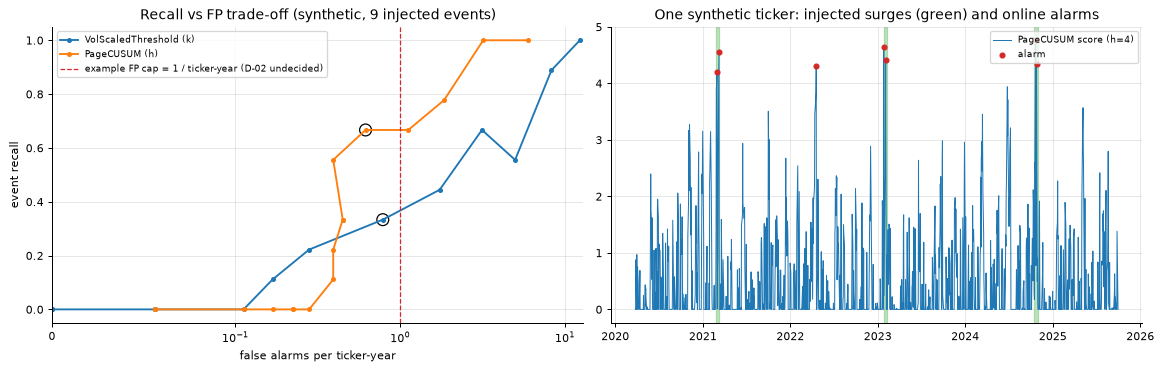

,detector,param,n_events,n_detected,n_missed,recall,n_fp,n_duplicate,n_suppressed,fp_per_ticker_year,alarm_precision,delay_mean,delay_median
0,VolScaledThreshold (k),3.0,9,2,7,0.222,5,0,0,0.280,0.286,1.500,1.5
1,VolScaledThreshold (k),4.0,9,0,9,0.000,1,0,0,0.056,0.000,NaN,NaN
2,PageCUSUM (h),3.0,9,7,2,0.778,33,0,4,1.848,0.175,2.429,3.0
3,PageCUSUM (h),4.0,9,6,3,0.667,11,0,2,0.616,0.353,3.000,3.0


In [11]:
from r2h.detection import PageCUSUM, VolScaledThreshold
from r2h.evaluation import MatchConfig, event_metrics, match_alarms, recall_at_fp_cap
from r2h.synthetic import InjectedSurge, ground_truth_from_injections, surge_series

surges = [InjectedSurge(s, 10, 0.012) for s in (300, 800, 1250)]
data = {f"SYN_{k}": surge_series(1500, surges, seed=20261012 + k) for k in range(3)}
cal = next(iter(data.values()))[1]
truth = pd.concat([ground_truth_from_injections(cal, surges, ticker=t) for t in data], ignore_index=True)
cfg = MatchConfig(max_delay=5, cooldown=5, direction=1)
ty = len(data) * len(cal) / 252
curves = {}
for name, make, grid in [
    ("VolScaledThreshold (k)", lambda v: VolScaledThreshold(window=60, k=v), np.arange(1.5, 5.01, 0.25)),
    ("PageCUSUM (h)", lambda v: PageCUSUM(window=60, drift=0.5, threshold=v), np.arange(2, 10.01, 0.5)),
]:
    res = []
    for v in grid:
        sig = pd.concat(
            [make(v).run(r, ticker=t, data_version="synthetic") for t, (r, _) in data.items()],
            ignore_index=True,
        )
        a, e = match_alarms(sig, truth, cal, cfg)
        res.append((float(v), event_metrics(a, e, ty)))
    curves[name] = res
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, res in curves.items():
    ax[0].plot([m.fp_per_ticker_year for _, m in res], [m.recall for _, m in res], "o-", ms=3, label=name)
    best = recall_at_fp_cap(res, fp_cap=1.0)
    if best:
        ax[0].scatter(best[1].fp_per_ticker_year, best[1].recall, s=90, facecolors="none", edgecolors="k")
ax[0].axvline(1.0, color="C3", ls="--", lw=1, label="example FP cap = 1 / ticker-year (D-02 undecided)")
ax[0].set_xlabel("false alarms per ticker-year")
ax[0].set_ylabel("event recall")
ax[0].set_xscale("symlog", linthresh=0.1)
ax[0].set_xlim(left=0)
ax[0].legend(fontsize=7)
ax[0].set_title("Recall vs FP trade-off (synthetic, 9 injected events)")
r0, _ = data["SYN_0"]
sig = PageCUSUM(window=60, drift=0.5, threshold=4.0).run(r0, ticker="SYN_0", data_version="synthetic")
ax[1].plot(cal, sig["score"], lw=0.8, label="PageCUSUM score (h=4)")
ax[1].scatter(sig.signal_at[sig.is_alarm], sig.score[sig.is_alarm], color="C3", s=15, zorder=3, label="alarm")
for s in surges:
    ax[1].axvspan(cal[s.start], cal[s.start + s.length - 1], color="C2", alpha=0.3)
ax[1].set_title("One synthetic ticker: injected surges (green) and online alarms")
ax[1].legend(fontsize=7)
plt.tight_layout()
show(fig, "r2h_synthetic_tradeoff")
pd.DataFrame(
    [
        {"detector": n, "param": v, **m.as_dict()}
        for n, res in curves.items()
        for v, m in res
        if v in (3.0, 4.0)
    ]
).round(3)

**해석 (계약 시연)**
- 같은 정답·매칭 규칙(`max_delay=5`, `cooldown=5`)에서 두 탐지기의 **탐지율–오탐 곡선**을 그릴 수 있다. 2조 CUSUM 과 4조 BOCPD 도 같은 출력 계약만 지키면 이 그림에 같이 올라간다.
- 원은 `recall_at_fp_cap(fp_cap=1)` 이 고른 설정이다. 실제 상한값·지연 허용·cooldown 은 교수 확인 전이며(D-02), 임계값 선택은 **개발 구간에서만** 한다.
- 오른쪽 그림처럼 경보는 t 시점까지의 관측만 쓴다(`available_until ≤ signal_at`, 누수 테스트로 강제). 사후 검정(3절)은 이 그림에 넣을 수 없다.

## 5. 종합

| 구분 | 내용 | 근거 |
|---|---|---|
| **재현으로 확인됨** | EDA 결과표 309종 바이트 동일 · Track A 결과표 43종 독립 2회 동일 · Track B 실증·MC 결정적 재현 | 1–3절, `research/REPRODUCTION_STATUS.md` |
| **반증/부정적 결과** | 상관 전환 → 급등 선행성 미입증 (같은 날 기계적 중복 제거 시 18→1, 9/48→0/48) | 2절 |
| **원문 미재현** | SVR–GARCH CUSUM: CI 포함 1/45 (사전등록), 실증 3종 비기각 vs 원문 기각 | 3절 |
| **보고서 정정** | Track A "평균 11.1 달력일" = C3 전 변형 평균 (주 정의 9거래일≈13.4일) · "lag 0 최대" 는 WTI 예외 | 2절, REPRODUCTION_STATUS |
| **팀 기준선 (R2H 1012)** | 관측·feature·탐지 출력(online/posthoc)·정답·매칭·지표·분할·백테스트 스키마 계약 v0.1 + 테스트 83 + CI | 4절, `docs/architecture/CONTRACT_v0.1.md` |
| **미결 (교수·4조)** | D-01 Ground Truth 정의 · D-02 오탐 상한/지연/cooldown · D-03 구간 경계와 2026 처리 · D-07 LICENSE | `docs/decisions/OPEN_DECISIONS.md` |

**다음 단계**: 10/12 미팅 결정 → 계약 v0.2 → 승인된 정답으로 개발 구간 임계값 선택 → 검증 구간 walk-forward 로 CUSUM vs BOCPD vs 규칙 baseline 비교 → 백테스트 계약 위 진입·청산 규칙.